# Pipeline klasyfikacji języka mowy (Grecki vs Serbski)

In [1]:
%load_ext autoreload
%autoreload 2

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.audio_processing import (
    apply_highpass_filter,
    audit_and_load_dataset,
    compute_envelope,
    get_speaker_by_label,
)
from src.feature_extraction import build_feature_dataframe
from src.data_balancing import (
    balance_speaker_groups,
    stratified_speaker_train_test_split,
    get_group_statistics,
)
from src.modeling import (
    check_gpu_availability,
    create_classifier,
    train_and_evaluate,
    run_group_cross_validation,
    analyze_model_stability,
    run_multiseed_experiment,
)
from src.visualization import (
    create_chart,
    plot_speaker_fragments,
    plot_speaker_comparison,
    plot_group_balance,
    plot_feature_importances,
    plot_confusion_matrix,
    plot_cv_stability,
    plot_feature_stability,
    plot_multiseed_stability,
)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.precision', 3)

gpu_status = check_gpu_availability()
print('Status akceleracji sprzętowej:', gpu_status)


Status akceleracji sprzętowej: {'cuda_available': True, 'device_name': 'NVIDIA CUDA Device', 'backend': 'XGBoost CUDA'}


In [2]:
data_folders = {
    'Greek': 'Greek',
    'Serbian': 'Serbian',
}

target_sr = 32000
window_size = 1000
silence_threshold = 0.002
highpass_cutoff = 75.0
max_clips_per_language = 2000
feature_mode = 'rhythm'
random_state = 42

In [3]:
raw_speakers_data, silence_audit_df = audit_and_load_dataset(
    folder_configs=data_folders,
    max_clips_per_language=max_clips_per_language,
    target_sr=target_sr,
    window_size=window_size,
    silence_threshold=silence_threshold,
    highpass_cutoff=highpass_cutoff,
)

print('Raport analizy ciszy z filtrem górnoprzepustowym (75 Hz) przed przetworzeniem:')
display(silence_audit_df)
print(f'\nŁącznie zachowano {len(raw_speakers_data)} poprawnych mówców (usunięto ciche i uszkodzone nagrania).')

Raport analizy ciszy z filtrem górnoprzepustowym (75 Hz) przed przetworzeniem:


,Język,Wczytane nagrania,Łączny czas audio (s),Śr. długość nagrania (s),Wszystkie fragmenty 1s,Aktywne fragmenty (mowa),Odrzucona cisza (< 0.002),Odsetek ciszy (%),Usunięte ciche nagrania (błędne),Pozostali poprawni mówcy
0,Greek,2000,8312.5,4.16,7281,6467,814,11.18%,16,1984
1,Serbian,2000,6605.2,3.30,5603,4985,618,11.03%,38,1962



Łącznie zachowano 3946 poprawnych mówców (usunięto ciche i uszkodzone nagrania).


Lewa kolumna (Grek): Greek (Speaker_1126), fragmenty: 2
Prawa kolumna (Serb): Serbian (Speaker_3110), fragmenty: 2


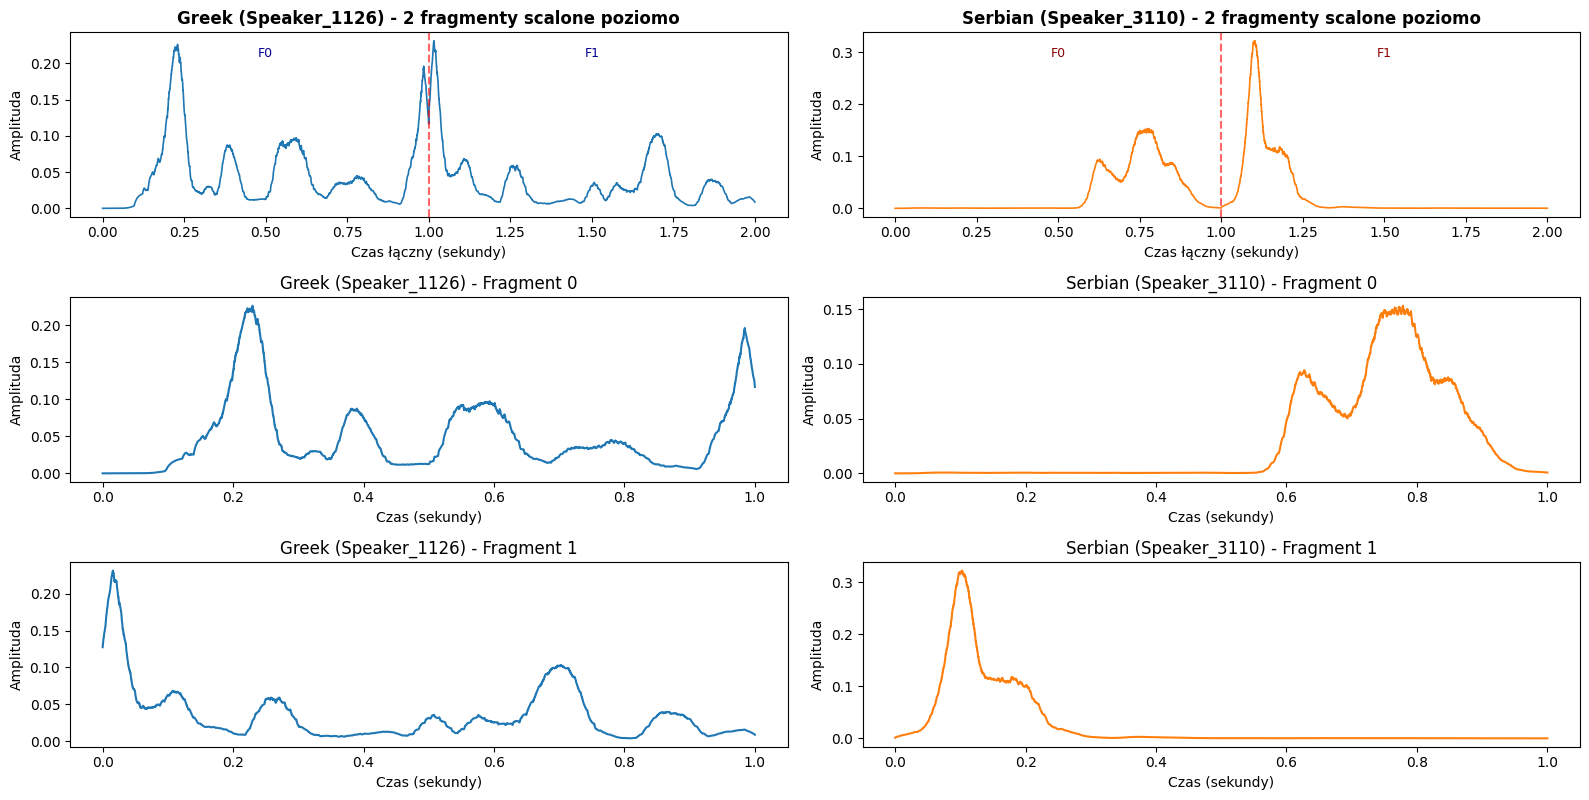

In [4]:
greek_speaker = get_speaker_by_label(raw_speakers_data, label='Greek', random_state=random_state)
serbian_speaker = get_speaker_by_label(raw_speakers_data, label='Serbian', random_state=random_state)

print(f"Lewa kolumna (Grek): {greek_speaker['label']} ({greek_speaker['speaker']}), fragmenty: {len(greek_speaker['fragments'])}")
print(f"Prawa kolumna (Serb): {serbian_speaker['label']} ({serbian_speaker['speaker']}), fragmenty: {len(serbian_speaker['fragments'])}")

plot_speaker_comparison(greek_speaker, serbian_speaker, max_fragments=4)

In [5]:
dataset_ml = build_feature_dataframe(
    raw_speakers_data,
    feature_mode=feature_mode,
)

print(f'Kształt datasetu ({feature_mode}): {dataset_ml.shape}')
dataset_ml.head(10)

Kształt datasetu (rhythm): (11452, 29)


,mean,std,max,skew,kurtosis,rms,crest_factor,mean_diff,std_diff,mean_peak_dist,...,rhythm_3hz,rhythm_4hz,rhythm_5hz,rhythm_6hz,rhythm_7hz,rhythm_8hz,rhythm_dominant_freq_hz,rhythm_syllabic_ratio,speaker,label
0,0.007,0.026,0.159,4.604,20.380,0.027,5.914,8.999e-06,4.153e-05,0.000,...,4.978,4.416,2.895,3.623,0.990,2.387,2.0,0.077,Speaker_0,Greek
1,0.051,0.038,0.138,0.590,-0.819,0.064,2.161,5.438e-05,9.330e-05,0.246,...,250.816,327.240,277.283,213.205,149.858,114.053,4.0,7.951,Speaker_0,Greek
2,0.016,0.014,0.058,0.793,-0.017,0.021,2.746,1.858e-05,3.636e-05,0.181,...,49.046,66.983,73.644,78.111,44.272,45.536,6.0,2.743,Speaker_0,Greek
3,0.029,0.048,0.187,1.645,1.676,0.056,3.324,3.020e-05,6.999e-05,0.192,...,213.705,190.091,185.780,166.396,131.853,100.694,2.0,1.089,Speaker_1,Greek
4,0.049,0.035,0.142,0.297,-1.035,0.060,2.374,5.016e-05,7.918e-05,0.152,...,141.615,195.004,148.691,166.168,78.673,55.973,4.0,5.527,Speaker_1,Greek
5,0.010,0.017,0.074,1.830,2.162,0.020,3.658,1.129e-05,3.054e-05,0.185,...,37.106,10.090,10.459,10.695,9.192,8.212,2.0,0.307,Speaker_1,Greek
6,0.018,0.024,0.110,1.766,2.687,0.030,3.676,1.913e-05,4.368e-05,0.208,...,94.896,157.126,150.535,84.427,2.067,57.489,4.0,1.699,Speaker_2,Greek
7,0.019,0.012,0.057,0.827,0.489,0.023,2.512,2.073e-05,3.127e-05,0.156,...,45.057,61.057,64.794,46.437,93.670,58.023,7.0,4.811,Speaker_2,Greek
8,0.015,0.011,0.054,1.297,2.186,0.019,2.906,1.684e-05,2.757e-05,0.196,...,11.470,22.423,37.775,67.456,46.418,20.551,6.0,11.951,Speaker_2,Greek
9,0.066,0.040,0.171,0.188,-0.356,0.077,2.222,5.498e-05,7.794e-05,0.190,...,174.791,102.036,206.697,92.483,24.130,85.614,5.0,1.919,Speaker_3,Greek


In [6]:
print('Rozkład przed wyrównaniem:')
stats_before = get_group_statistics(dataset_ml)
print(stats_before)

dataset_balanced = balance_speaker_groups(
    dataset_ml,
    max_samples_per_speaker=3,
    balance_speakers_per_class=True,
    balance_samples_per_class=True,
    random_state=random_state,
)

print('\nRozkład po wyrównaniu mówców i próbek:')
stats_after = get_group_statistics(dataset_balanced)
print(stats_after)

Rozkład przed wyrównaniem:
    Zbiór    Język  Liczba mówców  Liczba próbek (1s)  Łączny czas mowy (s)  \
0  Całość    Greek           1984                6467                6467.0   
1  Całość  Serbian           1962                4985                4985.0   

   Śr. czas / mówca (s)  
0                  3.26  
1                  2.54  

Rozkład po wyrównaniu mówców i próbek:
    Zbiór    Język  Liczba mówców  Liczba próbek (1s)  Łączny czas mowy (s)  \
0  Całość    Greek           1926                4369                4369.0   
1  Całość  Serbian           1962                4369                4369.0   

   Śr. czas / mówca (s)  
0                  2.27  
1                  2.23  


     Zbiór    Język  Liczba mówców  Liczba próbek (1s)  Łączny czas mowy (s)  \
0   Całość    Greek           1926                4369                4369.0   
1   Całość  Serbian           1962                4369                4369.0   
2  Trening  Serbian           1472                3280                3280.0   
3  Trening    Greek           1444                3259                3259.0   
4     Test    Greek            482                1110                1110.0   
5     Test  Serbian            490                1089                1089.0   

   Śr. czas / mówca (s)  
0                  2.27  
1                  2.23  
2                  2.23  
3                  2.26  
4                  2.30  
5                  2.22  


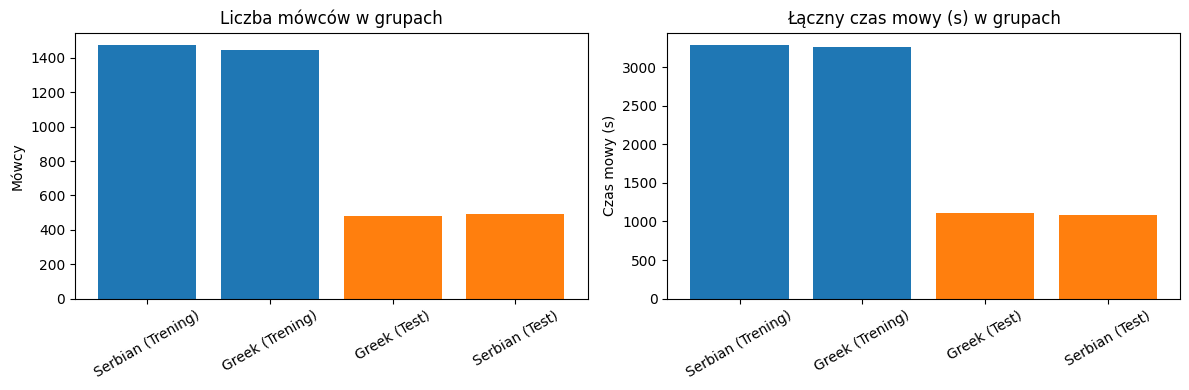

In [7]:
X_train, y_train, X_test, y_test, speakers_train, speakers_test, train_df, test_df = (
    stratified_speaker_train_test_split(
        dataset_balanced,
        test_size=0.25,
        random_state=random_state,
    )
)

split_stats = get_group_statistics(dataset_balanced, speakers_train, speakers_test)
print(split_stats)
plot_group_balance(split_stats)

In [8]:
model = create_classifier(model_type='gpu', random_state=random_state)

results = train_and_evaluate(
    model=model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    scale_features=True,
)

print('=' * 20 + ' RAPORT: ZBIÓR TRENINGOWY ' + '=' * 20)
print(results['report_train'])
print(f"Dokładność na zbiorze treningowym: {results['acc_train']:.2%}")

print('\n' + '=' * 20 + ' RAPORT: ZBIÓR TESTOWY ' + '=' * 20)
print(results['report_test'])
print(f"Dokładność na zbiorze testowym: {results['acc_test']:.2%}")

==================== RAPORT: ZBIÓR TRENINGOWY ====================
              precision    recall  f1-score   support

       Greek       0.74      0.71      0.72      3259
     Serbian       0.72      0.75      0.73      3280

    accuracy                           0.73      6539
   macro avg       0.73      0.73      0.73      6539
weighted avg       0.73      0.73      0.73      6539

Dokładność na zbiorze treningowym: 72.89%

==================== RAPORT: ZBIÓR TESTOWY ====================
              precision    recall  f1-score   support

       Greek       0.68      0.63      0.65      1110
     Serbian       0.65      0.70      0.67      1089

    accuracy                           0.66      2199
   macro avg       0.66      0.66      0.66      2199
weighted avg       0.66      0.66      0.66      2199

Dokładność na zbiorze testowym: 66.35%


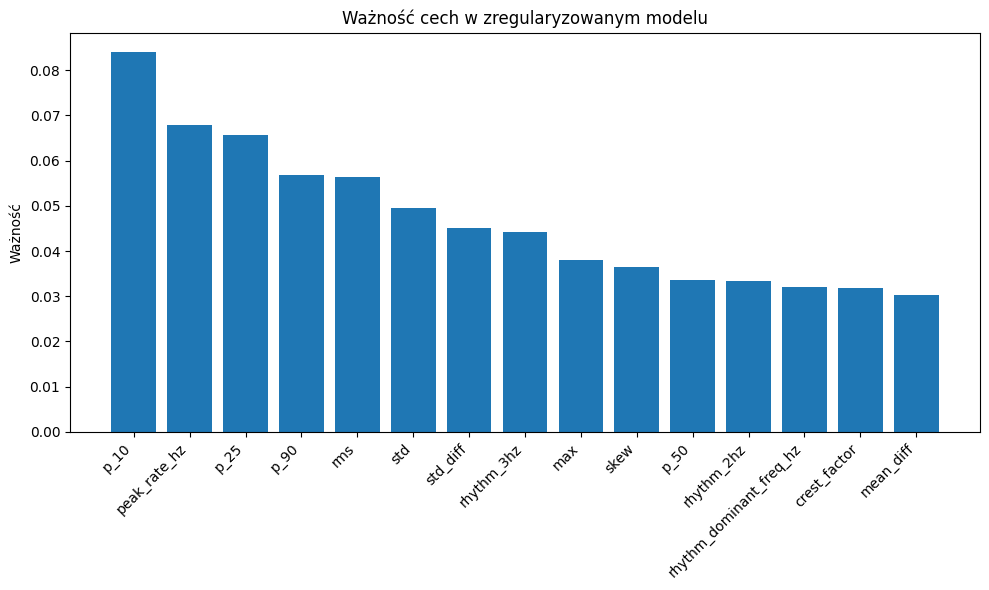

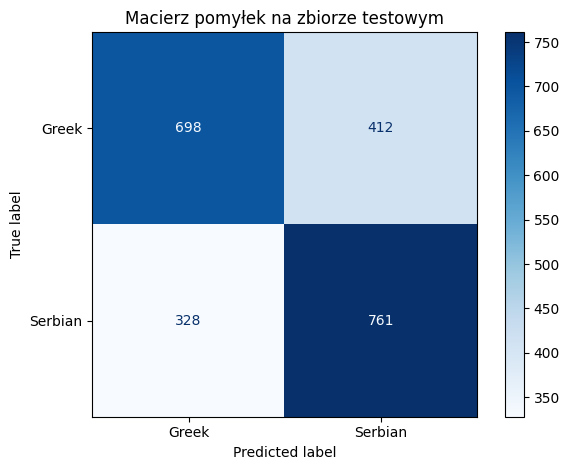

In [9]:
plot_feature_importances(
    model=results['model'],
    feature_names=X_train.columns,
    top_n=15,
    title='Ważność cech w zregularyzowanym modelu',
)

plot_confusion_matrix(
    cm=results['confusion_matrix'],
    classes=results['classes'],
    title='Macierz pomyłek na zbiorze testowym',
)

### 7. Grupowa walidacja krzyżowa (StratifiedGroupKFold) i analiza stabilności

Ocena modelu w 5-krotnej walidacji krzyżowej z podziałem grupowym wg mówców (brak wycieku mówców pomiędzy foldami).

========================= WYNIKI POSZCZEGÓLNYCH FOLDÓW =========================


,Fold,Trening Mówcy,Walidacja Mówcy,Train Accuracy,Val Accuracy,Generalization Gap,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,1,3110,778,0.727,0.667,0.060,0.658,0.697,0.677,0.730
1,2,3111,777,0.728,0.673,0.055,0.660,0.715,0.686,0.747
2,3,3110,778,0.723,0.681,0.041,0.677,0.692,0.685,0.751
3,4,3111,777,0.725,0.698,0.027,0.689,0.721,0.705,0.756
4,5,3110,778,0.728,0.677,0.051,0.679,0.669,0.674,0.726



========================= PODSUMOWANIE STATYSTYCZNE WALIDACJI =========================


,Metryka,Średnia (Mean),Odch. std (Std),Min,Max,Współczynnik zmienności (CV)
0,Train Accuracy,0.726,0.002,0.723,0.728,0.003
1,Val Accuracy,0.679,0.012,0.667,0.698,0.017
2,Generalization Gap,0.047,0.013,0.027,0.060,0.281
3,Val Precision,0.673,0.014,0.658,0.689,0.020
4,Val Recall,0.699,0.020,0.669,0.721,0.029
5,Val F1,0.685,0.012,0.674,0.705,0.017
6,Val ROC-AUC,0.742,0.013,0.726,0.756,0.018



========================= ANALIZA STABILNOŚCI MODELU =========================


,Wskaźnik,Wartość
0,Średnia dokładność walidacji (Val Acc),67.92%
1,Odch. std walidacji (Val Acc Std),1.17%
2,Współczynnik zmienności dokładności (CV = std/mean),0.0172
3,Średnia luka generalizacji (Train - Val),4.69%
4,Odch. std luki generalizacji (Gap Std),1.32%
5,Średni wynik F1 (Val F1),68.53%
6,Współczynnik zmienności F1 (CV),0.0174
7,Ocena stabilności modelu,Wysoka stabilność (brak przeuczenia)



========================= STABILNOŚĆ WAŻNOŚCI CECH MIĘDZY FOLDAMI =========================


,Cecha,Średnia ważność,Odch. std,Współczynnik zmienności
0,p_25,0.084,0.009,0.104
1,p_10,0.075,0.006,0.079
2,peak_rate_hz,0.060,0.003,0.057
3,rms,0.059,0.003,0.057
4,std_diff,0.048,0.002,0.033
5,p_90,0.048,0.009,0.196
6,std,0.047,0.007,0.148
7,rhythm_2hz,0.043,0.004,0.085
8,p_75,0.040,0.005,0.133
9,rhythm_3hz,0.039,0.006,0.155


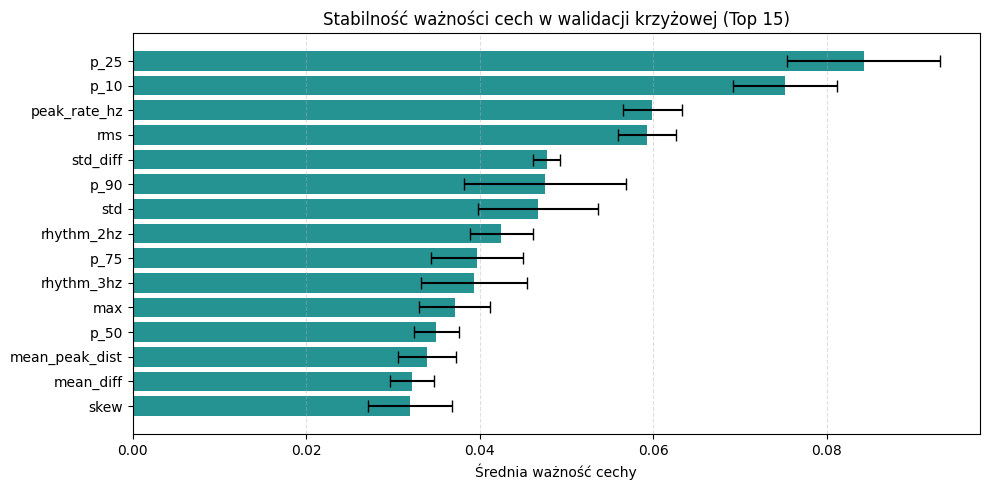

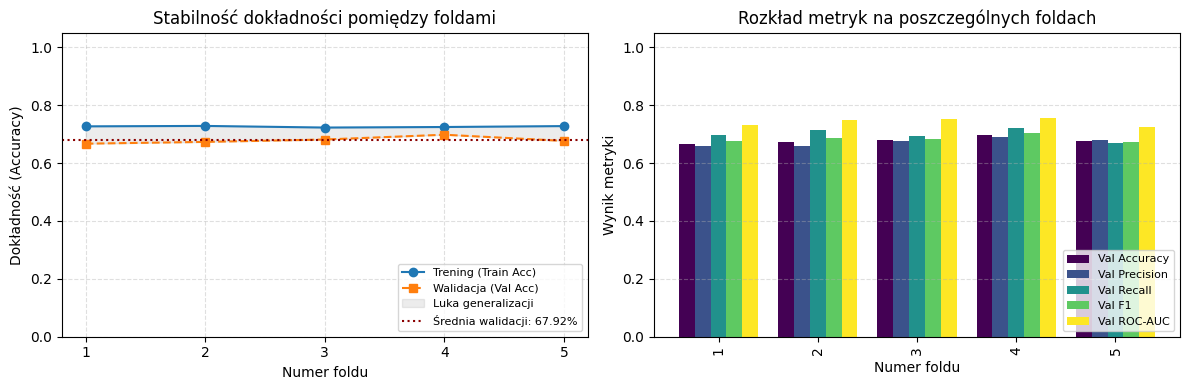

In [10]:
# 5-krotna walidacja grupowa (StratifiedGroupKFold)
cv_results = run_group_cross_validation(
    model=model,
    dataset=dataset_balanced,
    n_splits=5,
    scale_features=True,
    random_state=random_state,
)

print('=' * 25 + ' WYNIKI POSZCZEGÓLNYCH FOLDÓW ' + '=' * 25)
display(cv_results['fold_results'])

print('\n' + '=' * 25 + ' PODSUMOWANIE STATYSTYCZNE WALIDACJI ' + '=' * 25)
display(cv_results['summary'])

print('\n' + '=' * 25 + ' ANALIZA STABILNOŚCI MODELU ' + '=' * 25)
display(cv_results['stability_analysis'])

if cv_results['feature_stability'] is not None:
    print('\n' + '=' * 25 + ' STABILNOŚĆ WAŻNOŚCI CECH MIĘDZY FOLDAMI ' + '=' * 25)
    display(cv_results['feature_stability'].head(15))
    plot_feature_stability(cv_results['feature_stability'], top_n=15)

plot_cv_stability(cv_results['fold_results'])


### 8. Powtórzenie eksperymentu dla kilku ziaren losowości (Multi-seed Evaluation)

Wielokrotny podział zbioru na train/test (z zachowaniem rozłączności mówców) dla ziaren: `[42, 100, 2024, 7, 999]` celem oszacowania wariancji metryk, luki generalizacji i przedziału ufności 95%.

========================= WYNIKI DLA POSZCZEGÓLNYCH ZIAREN =========================


,Seed,Liczba mówców Train,Liczba mówców Test,Train Accuracy,Test Accuracy,Generalization Gap,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,42,2916,972,0.729,0.663,0.065,0.649,0.699,0.673,0.734
1,100,2916,972,0.728,0.685,0.043,0.667,0.719,0.692,0.751
2,2024,2916,972,0.732,0.682,0.050,0.677,0.700,0.689,0.744
3,7,2916,972,0.726,0.662,0.064,0.666,0.660,0.663,0.729
4,999,2916,972,0.726,0.670,0.056,0.656,0.716,0.685,0.734



========================= PODSUMOWANIE STATYSTYCZNE ZIAREN =========================


,Metryka,Średnia (Mean),Odch. std (Std),Min,Max,Współczynnik zmienności (CV)
0,Train Accuracy,0.728,0.002,0.726,0.732,0.003
1,Test Accuracy,0.673,0.010,0.662,0.685,0.015
2,Generalization Gap,0.056,0.009,0.043,0.065,0.168
3,Test Precision,0.663,0.011,0.649,0.677,0.017
4,Test Recall,0.699,0.023,0.660,0.719,0.033
5,Test F1,0.680,0.012,0.663,0.692,0.018
6,Test ROC-AUC,0.738,0.009,0.729,0.751,0.012



========================= RAPORT ODPORNOŚCI NA LOSOWY PODZIAŁ =========================


,Wskaźnik stabilności między ziarnami,Wartość
0,Liczba zbadanych ziaren losowości (Seeds),5
1,Średnia dokładność testowa (Mean Test Acc),67.26%
2,Odchylenie standardowe dokładności (Std),1.04%
3,Przedział ufności ok. 95% (Mean ± 2 Std),[65.19%; 69.33%]
4,Współczynnik zmienności dokładności (CV),0.0154
5,Średni wynik F1 na teście (Mean F1),68.03%
6,Odchylenie F1 (Std),1.19%
7,Średnia luka generalizacji (Train - Test),5.55%
8,Ocena odporności na losowość,Wysoka odporność na ziarno losowości


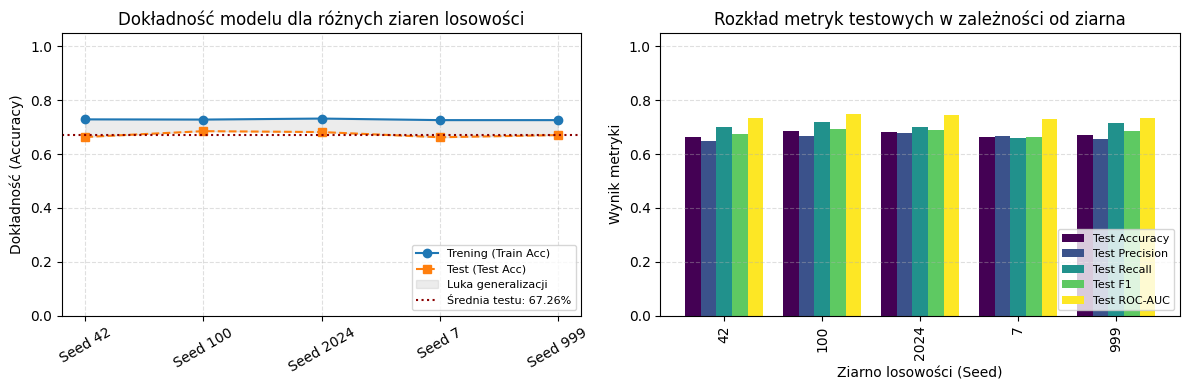

In [11]:
# Ewaluacja odporności na losowość podziału (multi-seed evaluation)
seeds_to_test = [42, 100, 2024, 7, 999]
multiseed_results = run_multiseed_experiment(
    model=model,
    dataset=dataset_balanced,
    seeds=seeds_to_test,
    test_size=0.25,
    scale_features=True,
)

print('=' * 25 + ' WYNIKI DLA POSZCZEGÓLNYCH ZIAREN ' + '=' * 25)
display(multiseed_results['seed_results'])

print('\n' + '=' * 25 + ' PODSUMOWANIE STATYSTYCZNE ZIAREN ' + '=' * 25)
display(multiseed_results['summary'])

print('\n' + '=' * 25 + ' RAPORT ODPORNOŚCI NA LOSOWY PODZIAŁ ' + '=' * 25)
display(multiseed_results['stability_report'])

plot_multiseed_stability(multiseed_results['seed_results'])
